# Independent Pushback Detection Evaluation

This notebook evaluates the final standalone PRD-TCN pushback detection pipeline from `03_final_model/pushback_prediction.py` and the two rule-based methods implemented in `traffic` on the manually labelled independent test datasets.

The cache can be selected per method:

```python
USE_CACHE_FOR = {
    "parking_area",
    "parking_position",
}
```

- `USE_CACHE_FOR = set(METHOD_ORDER)` reuses cached detections for all methods.
- `USE_CACHE_FOR = {"parking_area", "parking_position"}` reuses the two baseline methods and reruns PRD-TCN.
- `USE_CACHE_FOR = set()` reruns all methods.
- If a selected method has no cache for a dataset, it is executed automatically and the result is cached.
- `INCLUDE_NOT_CLEAR = False` excludes flights labelled as *not clear* from the reported evaluation without rerunning the detection methods.

The notebook reads trajectories from `data/test/01_fetched/`, labels from `data/test/02_labeled/`, and writes evaluation results to `results/evaluation/`.


In [1]:
# Standalone evaluation script for the paper
#
# Select cached methods and INCLUDE_NOT_CLEAR in the configuration section
# below, then run the notebook.

from __future__ import annotations

from dataclasses import asdict, dataclass
from functools import partial
from pathlib import Path
from typing import Callable, Iterable

import ast
import gc
import json
import os
import re
import sys
import traceback
import warnings

import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import pandas as pd

from traffic.core import Traffic


# =============================================================================
# Project paths
# =============================================================================

PROJECT_ROOT = Path.home() / "Projects" / "OSN_pushback_detection"

DATASET_ROOT = (
    PROJECT_ROOT
    / "data"
    / "test"
    / "01_fetched"
)

GROUND_TRUTH_ROOT = (
    PROJECT_ROOT
    / "data"
    / "test"
    / "02_labeled"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "evaluation"
)

CACHE_ROOT = OUTPUT_ROOT / "cache"
UNIT_OUTPUT_ROOT = OUTPUT_ROOT / "units"


# =============================================================================
# Standalone PRD-TCN prediction method
# =============================================================================

FINAL_MODEL_ROOT = PROJECT_ROOT / "03_final_model"

if str(FINAL_MODEL_ROOT) not in sys.path:
    sys.path.insert(0, str(FINAL_MODEL_ROOT))

import pushback_prediction as prd_tcn_prediction

predict_pushback = prd_tcn_prediction.predict_pushback



# =============================================================================
# Evaluation configuration
# =============================================================================

# A predicted segment is matched when it overlaps a GT segment and reaches
# this minimum temporal IoU. With 0.0, every positive overlap is eligible.
MIN_MATCH_IOU = 0.0

# Used for the dynamic F1-versus-IoU-threshold curve and its normalized AUC.
IOU_THRESHOLD_GRID = np.linspace(0.0, 1.0, 101)

METHOD_ORDER = [
    "prediction",
    "parking_area",
    "parking_position",
]

METHOD_LABELS = {
    "prediction": "PRD-TCN",
    "parking_area": "parking_area",
    "parking_position": "parking_position",
}


# -----------------------------------------------------------------------------
# User switches
# -----------------------------------------------------------------------------

# Methods listed here use their cached detections when available.
#
# Typical development setup:
# - keep the unchanged baselines cached
# - rerun PRD-TCN
# USE_CACHE_FOR = {
#    "parking_area",
#    "parking_position",
# }

# Use cache for every method:
# USE_CACHE_FOR = set(METHOD_ORDER)

# Recompute every method:
USE_CACHE_FOR = set()

unknown_cached_methods = set(USE_CACHE_FOR) - set(METHOD_ORDER)
if unknown_cached_methods:
    raise ValueError(
        "Unknown method(s) in USE_CACHE_FOR: "
        f"{sorted(unknown_cached_methods)}"
    )

# False is the setting used for the paper. Not-clear flights are retained in
# the loaded ground truth and filtered only when the final results are built.
INCLUDE_NOT_CLEAR = False

# Continue with the remaining days when one dataset fails.
FAIL_ON_DATASET_ERROR = False


AVAILABLE_CPUS = max(
    1,
    int(
        os.environ.get(
            "SLURM_CPUS_PER_TASK",
            os.cpu_count() or 1,
        )
    ),
)

# All three methods use traffic's lazy evaluation pipeline for parallel
# flight-wise execution. PRD-TCN itself is still called directly through
# 03_final_model/pushback_prediction.py and is never routed through
# Flight.pushback(method="predict").
PUSHBACK_WORKERS = min(AVAILABLE_CPUS, 20)
PREDICTION_DEVICE = "cpu"
PREDICTION_CPU_THREADS = 1

SUPPORTED_TABLE_SUFFIXES = {
    ".parquet",
    ".csv",
    ".json",
    ".jsonl",
}

NOT_CLEAR_STATUSES = {
    "not clear",
    "not_clear",
    "not-clear",
    "unclear",
    "uncertain",
}

# These labels are genuinely not reviewed and are never evaluated. "Not clear"
# is deliberately not part of this set: it can be included or excluded through
# INCLUDE_NOT_CLEAR.
EXCLUDED_STATUSES = {
    "unlabeled",
    "not_labeled",
    "not labeled",
    "pending",
    "skip",
    "skipped",
    "invalid",
    "unknown",
}

SEASON_ORDER = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn",
]


## 1. Discover evaluation datasets

Each trajectory file below `data/test/01_fetched/<AIRPORT>/<SEASON>/` is treated as one evaluation unit and matched to the corresponding manually labelled ground-truth data below `data/test/02_labeled/`.


In [ ]:
@dataclass(frozen=True)
class DatasetUnit:
    dataset_id: str
    airport: str
    season: str
    day: str
    trajectory_path: str
    ground_truth_path: str

    @property
    def flight_prefix(self) -> str:
        return self.dataset_id.replace("/", "__")


def ordered_unique(values: Iterable[str]) -> list[str]:
    return list(dict.fromkeys(str(value) for value in values))


def season_sort_key(season: str) -> tuple[int, str]:
    try:
        return (SEASON_ORDER.index(str(season)), str(season))
    except ValueError:
        return (len(SEASON_ORDER), str(season))


def resolve_ground_truth_path(
    trajectory_path: Path,
) -> Path | None:
    relative = trajectory_path.relative_to(DATASET_ROOT)
    relative_without_suffix = relative.with_suffix("")

    candidates = [
        GROUND_TRUTH_ROOT / relative_without_suffix,
        GROUND_TRUTH_ROOT / relative,
    ]

    base = GROUND_TRUTH_ROOT / relative_without_suffix
    candidates.extend(
        base.with_suffix(suffix)
        for suffix in sorted(SUPPORTED_TABLE_SUFFIXES)
    )

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


def discover_dataset_manifest() -> pd.DataFrame:
    if not DATASET_ROOT.exists():
        raise FileNotFoundError(
            f"Dataset root not found: {DATASET_ROOT}"
        )

    if not GROUND_TRUTH_ROOT.exists():
        raise FileNotFoundError(
            f"Ground-truth root not found: {GROUND_TRUTH_ROOT}"
        )

    rows = []

    for trajectory_path in sorted(DATASET_ROOT.rglob("*.parquet")):
        if not trajectory_path.is_file():
            continue

        relative = trajectory_path.relative_to(DATASET_ROOT)

        if len(relative.parts) < 3:
            warnings.warn(
                "Skipped trajectory file outside the expected "
                "data/test/01_fetched/<AIRPORT>/<SEASON>/<DAY>.parquet structure: "
                f"{trajectory_path}"
            )
            continue

        airport = relative.parts[0].upper()
        season = relative.parts[1]
        day = trajectory_path.stem
        dataset_id = relative.with_suffix("").as_posix()
        ground_truth_path = resolve_ground_truth_path(trajectory_path)

        rows.append(
            {
                "dataset_id": dataset_id,
                "airport": airport,
                "season": season,
                "day": day,
                "trajectory_path": str(trajectory_path),
                "ground_truth_path": (
                    None
                    if ground_truth_path is None
                    else str(ground_truth_path)
                ),
                "status": (
                    "ready"
                    if ground_truth_path is not None
                    else "missing_ground_truth"
                ),
            }
        )

    manifest = pd.DataFrame(rows)

    if manifest.empty:
        raise ValueError(
            f"No parquet datasets found below {DATASET_ROOT}."
        )

    manifest = manifest.sort_values(
        ["airport", "season", "day", "dataset_id"],
        key=lambda column: (
            column.map(season_sort_key)
            if column.name == "season"
            else column
        ),
    ).reset_index(drop=True)

    duplicate_ids = manifest["dataset_id"].duplicated(keep=False)
    if duplicate_ids.any():
        raise ValueError(
            "Duplicate dataset IDs found:\n"
            + manifest.loc[duplicate_ids, "dataset_id"].to_string(index=False)
        )

    return manifest


manifest = discover_dataset_manifest()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
manifest.to_csv(OUTPUT_ROOT / "dataset_manifest.csv", index=False)

print(manifest.to_string(index=False))

missing_ground_truth = manifest.loc[
    manifest["status"].eq("missing_ground_truth")
]

if not missing_ground_truth.empty:
    warnings.warn(
        "The following trajectory datasets have no matching ground truth and "
        "will be skipped:\n"
        + missing_ground_truth[
            ["dataset_id", "trajectory_path"]
        ].to_string(index=False)
    )

ready_manifest = manifest.loc[
    manifest["status"].eq("ready")
].reset_index(drop=True)

if ready_manifest.empty:
    raise ValueError("No dataset has both trajectories and ground truth.")


          dataset_id airport season      day                                                                                      trajectory_path                                                                            ground_truth_path status
EBBR/Winter/05-12-25    EBBR Winter 05-12-25 /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/01_fetched/EBBR/Winter/05-12-25.parquet /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/02_labeled/EBBR/Winter/05-12-25  ready
EBBR/Spring/18-04-25    EBBR Spring 18-04-25 /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/01_fetched/EBBR/Spring/18-04-25.parquet /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/02_labeled/EBBR/Spring/18-04-25  ready
EBBR/Summer/17-07-25    EBBR Summer 17-07-25 /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/01_fetched/EBBR/Summer/17-07-25.parquet /cluster/home/hanv/Projects/OSN_pushback_detection/data/test/02_labeled/EBBR/Summer/17-07-25  ready
EBBR/Autumn/05-1

## 2. Load manually labelled ground truth

The loader supports flight-level labels, complete pushback segments, and optional push/pull subsegments. Flights marked as *not clear* are retained at this stage and are filtered only when the final paper results are generated.


In [ ]:
def find_column(
    data: pd.DataFrame,
    names: list[str],
) -> str | None:
    lookup = {
        str(column).strip().lower(): column
        for column in data.columns
    }

    return next(
        (
            lookup[name.lower()]
            for name in names
            if name.lower() in lookup
        ),
        None,
    )


def read_table(path: Path) -> pd.DataFrame | None:
    try:
        suffix = path.suffix.lower()

        if suffix == ".parquet":
            return pd.read_parquet(path)

        if suffix == ".csv":
            return pd.read_csv(path)

        if suffix == ".jsonl":
            return pd.read_json(path, lines=True)

        if suffix == ".json":
            try:
                return pd.read_json(path)
            except ValueError:
                content = json.loads(path.read_text(encoding="utf-8"))

                if isinstance(content, list):
                    return pd.DataFrame(content)

                if isinstance(content, dict):
                    for key in [
                        "annotations",
                        "labels",
                        "records",
                        "data",
                    ]:
                        if isinstance(content.get(key), list):
                            return pd.DataFrame(content[key])

    except Exception as error:
        warnings.warn(f"Could not read {path}: {error}")

    return None


def parse_structured_value(value):
    """Parse JSON/Python-literal values while preserving ordinary strings."""
    if value is None:
        return None

    if isinstance(value, float) and np.isnan(value):
        return None

    if not isinstance(value, str):
        return value

    stripped = value.strip()
    if not stripped:
        return None

    try:
        return json.loads(stripped)
    except (json.JSONDecodeError, TypeError):
        try:
            return ast.literal_eval(stripped)
        except (ValueError, SyntaxError):
            return stripped


def normalized_key(value) -> str:
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")


def interval_from_mapping(value: dict) -> tuple[pd.Timestamp, pd.Timestamp] | None:
    start = None
    end = None

    for key in [
        "start_ts",
        "start",
        "segment_start",
        "pushback_start",
        "begin",
        "from",
    ]:
        if key in value:
            start = value[key]
            break

    for key in [
        "end_ts",
        "end",
        "segment_end",
        "pushback_end",
        "stop",
        "to",
    ]:
        if key in value:
            end = value[key]
            break

    start = pd.to_datetime(start, errors="coerce", utc=True)
    end = pd.to_datetime(end, errors="coerce", utc=True)

    if pd.isna(start) or pd.isna(end):
        return None

    return min(start, end), max(start, end)


def parse_segments(value) -> list[tuple[pd.Timestamp, pd.Timestamp]]:
    """Parse the overall pushback interval(s), not nested push/pull phases."""
    parsed = parse_structured_value(value)

    if parsed is None:
        return []

    if isinstance(parsed, dict):
        for key in ["pushback_segments", "pb_segments", "segments"]:
            if key in parsed and isinstance(parsed[key], (list, tuple)):
                parsed = parsed[key]
                break
        else:
            parsed = [parsed]

    if not isinstance(parsed, (list, tuple)):
        return []

    intervals: list[tuple[pd.Timestamp, pd.Timestamp]] = []

    for segment in parsed:
        if isinstance(segment, dict):
            interval = interval_from_mapping(segment)
        elif isinstance(segment, (list, tuple)) and len(segment) >= 2:
            start = pd.to_datetime(segment[0], errors="coerce", utc=True)
            end = pd.to_datetime(segment[1], errors="coerce", utc=True)
            interval = (
                (min(start, end), max(start, end))
                if pd.notna(start) and pd.notna(end)
                else None
            )
        else:
            interval = None

        if interval is not None:
            intervals.append(interval)

    return list(dict.fromkeys(intervals))


def canonical_label_status(value, has_pushback: bool = False) -> str:
    raw = normalized_key(value) if value is not None else ""

    if raw in {normalized_key(item) for item in NOT_CLEAR_STATUSES}:
        return "not clear"

    if raw in {
        "pushback",
        "pb",
        "has_pushback",
        "positive",
        "yes",
        "true",
        "1",
    }:
        return "pushback"

    if raw in {
        "no_pushback",
        "no_pb",
        "negative",
        "none",
        "no",
        "false",
        "0",
    }:
        return "no pushback"

    if raw:
        return str(value).strip().lower()

    return "pushback" if has_pushback else "reviewed"


def parse_tags(value) -> list[str]:
    parsed = parse_structured_value(value)

    if parsed is None:
        return []

    if isinstance(parsed, dict):
        result = []
        for key, nested in parsed.items():
            if "tag" in normalized_key(key):
                result.extend(parse_tags(nested))
        return result

    if isinstance(parsed, (list, tuple, set)):
        result = []
        for nested in parsed:
            result.extend(parse_tags(nested))
        return result

    text = str(parsed).strip()
    if not text:
        return []

    return [
        item.strip()
        for item in re.split(r"[|;,]", text)
        if item.strip()
    ]


def extract_nested_tags(value) -> list[str]:
    parsed = parse_structured_value(value)
    result: list[str] = []

    def walk(item):
        if isinstance(item, dict):
            for key, nested in item.items():
                if "tag" in normalized_key(key):
                    result.extend(parse_tags(nested))
                walk(nested)
        elif isinstance(item, (list, tuple)):
            for nested in item:
                walk(nested)

    walk(parsed)
    return result


def normalize_push_pull_type(value) -> str | None:
    normalized = normalized_key(value)

    if normalized == "push" or normalized.startswith("push_"):
        return "push"
    if normalized == "pull" or normalized.startswith("pull_"):
        return "pull"

    return None


def extract_push_pull_subsegments(
    value,
    forced_type: str | None = None,
) -> list[dict]:
    """Recursively find explicitly typed push/pull subsegments."""
    parsed = parse_structured_value(value)
    found: list[dict] = []

    def add_segment(segment_type: str, item, fallback_index: int):
        interval = interval_from_mapping(item) if isinstance(item, dict) else None

        if interval is None and isinstance(item, (list, tuple)) and len(item) >= 2:
            start = pd.to_datetime(item[0], errors="coerce", utc=True)
            end = pd.to_datetime(item[1], errors="coerce", utc=True)
            if pd.notna(start) and pd.notna(end):
                interval = (min(start, end), max(start, end))

        found.append(
            {
                "type": segment_type,
                "start": None if interval is None else interval[0],
                "end": None if interval is None else interval[1],
                "fallback_index": fallback_index,
            }
        )

    counter = 0

    def walk(item, inherited_type: str | None = None):
        nonlocal counter
        counter += 1
        current_index = counter

        if isinstance(item, dict):
            explicit_type = inherited_type
            for type_key in [
                "type",
                "segment_type",
                "movement_type",
                "action",
                "phase",
                "kind",
                "class",
                "label",
            ]:
                if type_key in item:
                    explicit_type = normalize_push_pull_type(item[type_key]) or explicit_type
                    break

            if explicit_type in {"push", "pull"} and interval_from_mapping(item):
                add_segment(explicit_type, item, current_index)

            for key, nested in item.items():
                key_type = normalize_push_pull_type(key)
                if key_type is None:
                    normalized = normalized_key(key)
                    if normalized in {"push_segments", "push_subsegments"}:
                        key_type = "push"
                    elif normalized in {"pull_segments", "pull_subsegments"}:
                        key_type = "pull"

                walk(nested, key_type or explicit_type)

        elif isinstance(item, (list, tuple)):
            if inherited_type in {"push", "pull"}:
                if len(item) >= 2 and not any(
                    isinstance(nested, (dict, list, tuple))
                    for nested in item[:2]
                ):
                    add_segment(inherited_type, item, current_index)
                    return

            for nested in item:
                walk(nested, inherited_type)

    walk(parsed, forced_type)

    deduplicated = {}
    for item in found:
        start = item["start"]
        end = item["end"]
        key = (
            item["type"],
            None if start is None else pd.Timestamp(start).isoformat(),
            None if end is None else pd.Timestamp(end).isoformat(),
        )
        if key[1] is None and key[2] is None:
            key = (*key, item["fallback_index"])
        deduplicated[key] = item

    return list(deduplicated.values())


def choose_flight_status(statuses: set[str], has_pushback: bool) -> str:
    if "not clear" in statuses:
        return "not clear"
    if "pushback" in statuses:
        return "pushback"
    if "no pushback" in statuses:
        return "no pushback"

    meaningful = sorted(status for status in statuses if status and status != "reviewed")
    if meaningful:
        return meaningful[0]

    return "pushback" if has_pushback else "reviewed"


def load_ground_truth(
    path: Path,
) -> tuple[pd.DataFrame, list[str], pd.DataFrame, pd.DataFrame]:
    """
    Load all reviewed flights, including ``not clear``. The returned flight
    metadata contains label status, tags and push/pull subsegment counts so the
    dashboard can include/exclude and filter these flights without rerunning the
    model methods.
    """
    if not path.exists():
        raise FileNotFoundError(path)

    if path.is_file():
        files = [path]
    else:
        files = sorted(
            file
            for file in path.rglob("*")
            if (
                file.is_file()
                and file.suffix.lower() in SUPPORTED_TABLE_SUFFIXES
            )
        )

    segment_rows = []
    metadata: dict[str, dict] = {}
    loaded_files = []

    def metadata_for(flight_id: str) -> dict:
        return metadata.setdefault(
            str(flight_id),
            {
                "statuses": set(),
                "tags": set(),
                "push_subsegments": set(),
                "pull_subsegments": set(),
                "subsegment_records": {},
                "source_files": set(),
            },
        )

    for file in files:
        data = read_table(file)

        if data is None or data.empty:
            continue

        flight_column = find_column(data, ["flight_id", "flight id"])
        if flight_column is None:
            continue

        data = data.copy()
        data[flight_column] = data[flight_column].astype(str)

        status_column = find_column(
            data,
            ["flight_status", "label_status", "status"],
        )
        segment_column = find_column(
            data,
            ["pushback_segments", "pb_segments"],
        )
        start_column = find_column(
            data,
            ["segment_start", "start_ts", "pushback_start"],
        )
        end_column = find_column(
            data,
            ["segment_end", "end_ts", "pushback_end"],
        )
        labelled_at_column = find_column(
            data,
            ["labelled_at", "labeled_at", "updated_at"],
        )

        tag_columns = [
            column
            for column in data.columns
            if "tag" in normalized_key(column)
        ]
        subsegment_columns: list[tuple[str, str | None]] = []
        for column in data.columns:
            normalized = normalized_key(column)
            forced_type = None
            if "push" in normalized and "segment" in normalized and column != segment_column:
                forced_type = "push"
            elif "pull" in normalized and "segment" in normalized:
                forced_type = "pull"
            elif normalized in {
                "subsegments",
                "sub_segments",
                "push_pull_segments",
                "push_pull_subsegments",
                "movement_segments",
                "maneuver_segments",
                "phases",
            }:
                forced_type = None
            else:
                continue
            subsegment_columns.append((column, forced_type))

        status = (
            data[status_column]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
            if status_column is not None
            else pd.Series("", index=data.index)
        )

        has_segment = (
            data[segment_column].map(lambda item: bool(parse_segments(item)))
            if segment_column is not None
            else pd.Series(False, index=data.index)
        )
        has_label_timestamp = (
            data[labelled_at_column].notna()
            if labelled_at_column is not None
            else pd.Series(False, index=data.index)
        )
        has_start_end = (
            data[start_column].notna() & data[end_column].notna()
            if start_column is not None and end_column is not None
            else pd.Series(False, index=data.index)
        )

        # A flight is considered reviewed when an explicit status, labelled
        # timestamp, or complete pushback interval is available.
        reviewed_evidence = (
            status.ne("")
            | has_segment
            | has_label_timestamp
            | has_start_end
        )
        excluded = status.map(normalized_key).isin(
            {normalized_key(item) for item in EXCLUDED_STATUSES}
        )
        reviewed_mask = reviewed_evidence & ~excluded
        data = data.loc[reviewed_mask].copy()

        if data.empty:
            continue

        detected_structure = []

        for _, row in data.iterrows():
            flight_id = str(row[flight_column])
            flight_meta = metadata_for(flight_id)
            flight_meta["source_files"].add(str(file))

            row_segments = (
                parse_segments(row[segment_column])
                if segment_column is not None
                else []
            )
            row_status = canonical_label_status(
                row[status_column] if status_column is not None else None,
                has_pushback=bool(row_segments),
            )
            flight_meta["statuses"].add(row_status)

            for column in tag_columns:
                flight_meta["tags"].update(parse_tags(row[column]))

            if segment_column is not None:
                flight_meta["tags"].update(
                    extract_nested_tags(row[segment_column])
                )

            subsegments = []
            if segment_column is not None:
                subsegments.extend(
                    extract_push_pull_subsegments(row[segment_column])
                )
            for column, forced_type in subsegment_columns:
                subsegments.extend(
                    extract_push_pull_subsegments(
                        row[column],
                        forced_type=forced_type,
                    )
                )

            for subsegment in subsegments:
                start = subsegment["start"]
                end = subsegment["end"]
                segment_type = subsegment["type"]
                key = (
                    segment_type,
                    None if start is None else pd.Timestamp(start).isoformat(),
                    None if end is None else pd.Timestamp(end).isoformat(),
                )
                if key[1] is None and key[2] is None:
                    key = (*key, len(flight_meta["subsegment_records"]))

                flight_meta["subsegment_records"][key] = {
                    "type": segment_type,
                    "start": None if start is None else pd.Timestamp(start).isoformat(),
                    "end": None if end is None else pd.Timestamp(end).isoformat(),
                }
                flight_meta[f"{segment_type}_subsegments"].add(key)

        if segment_column is not None:
            detected_structure.append("pushback_segments")
            for _, row in data.iterrows():
                flight_id = str(row[flight_column])
                for start, end in parse_segments(row[segment_column]):
                    segment_rows.append(
                        {
                            "flight_id": flight_id,
                            "segment_start": start,
                            "segment_end": end,
                            "source_file": str(file),
                        }
                    )

        elif start_column is not None and end_column is not None:
            detected_structure.append("start/end")
            for _, row in data.iterrows():
                flight_id = str(row[flight_column])
                start = pd.to_datetime(
                    row[start_column], errors="coerce", utc=True
                )
                end = pd.to_datetime(
                    row[end_column], errors="coerce", utc=True
                )
                if pd.notna(start) and pd.notna(end):
                    segment_rows.append(
                        {
                            "flight_id": flight_id,
                            "segment_start": min(start, end),
                            "segment_end": max(start, end),
                            "source_file": str(file),
                        }
                    )


        if detected_structure:
            loaded_files.append(
                {
                    "file": str(file),
                    "rows": len(data),
                    "structure": ", ".join(detected_structure),
                }
            )

    if not metadata:
        raise ValueError(
            "No labelled flights were found. Expected flight_id together "
            "with pushback_segments or explicit start/end columns."
        )

    ground_truth = pd.DataFrame(segment_rows)
    if ground_truth.empty:
        ground_truth = pd.DataFrame(
            columns=[
                "flight_id",
                "segment_start",
                "segment_end",
                "source_file",
            ]
        )
    else:
        ground_truth = (
            ground_truth.drop_duplicates(
                ["flight_id", "segment_start", "segment_end"]
            )
            .sort_values(["flight_id", "segment_start"])
            .reset_index(drop=True)
        )

    gt_flights = set(ground_truth["flight_id"].astype(str))
    metadata_rows = []
    for flight_id, values in metadata.items():
        status = choose_flight_status(
            values["statuses"],
            has_pushback=flight_id in gt_flights,
        )
        tags = sorted(str(tag) for tag in values["tags"] if str(tag).strip())
        subsegment_records = list(values["subsegment_records"].values())

        metadata_rows.append(
            {
                "flight_id": str(flight_id),
                "label_status": status,
                "is_not_clear": status == "not clear",
                "tags": " | ".join(tags),
                "tags_json": json.dumps(tags, ensure_ascii=False),
                "push_subsegments": len(values["push_subsegments"]),
                "pull_subsegments": len(values["pull_subsegments"]),
                "total_push_pull_subsegments": (
                    len(values["push_subsegments"])
                    + len(values["pull_subsegments"])
                ),
                "push_pull_subsegments_json": json.dumps(
                    subsegment_records,
                    ensure_ascii=False,
                ),
                "label_source_files": " | ".join(
                    sorted(values["source_files"])
                ),
            }
        )

    flight_metadata = pd.DataFrame(metadata_rows).sort_values("flight_id")
    ground_truth = ground_truth.merge(
        flight_metadata,
        on="flight_id",
        how="left",
        validate="many_to_one",
    )

    return (
        ground_truth,
        sorted(metadata),
        flight_metadata.reset_index(drop=True),
        pd.DataFrame(loaded_files),
    )


## 3. Evaluate each dataset unit

The PRD-TCN prediction method and both rule-based `traffic` methods are evaluated on every labelled flight.

All three methods are executed through `Traffic.iterate_lazy().pipe(...).eval(...)`. For PRD-TCN, the function passed to `pipe()` calls the standalone `03_final_model/pushback_prediction.py::predict_pushback` implementation directly; it does not use `Flight.pushback(method="predict")`.

Detected segments are cached **separately for each method and dataset** under `results/evaluation/cache/`. The methods listed in `USE_CACHE_FOR` reuse their cached detections when available; all other methods are executed again and their cache is updated.

This makes it possible to keep the unchanged `parking_area` and `parking_position` baselines cached while rerunning PRD-TCN during model development.

Segment boundaries are taken directly from `segment.start` and `segment.stop`; the evaluation does not reconstruct segments from individual trajectory points.


In [ ]:
def baseline_pushback_safe(
    flight,
    airport: str,
    method: str,
):
    """Apply one rule-based traffic pushback method and skip failing flights."""
    try:
        return flight.pushback(
            airport=airport,
            method=method,
        )

    except Exception as error:
        flight_id = getattr(flight, "flight_id", "unknown")
        print(
            f"{method} skipped {flight_id}: "
            f"{type(error).__name__}: {error}"
        )
        return None


def prediction_pushback_safe(
    flight,
    airport: str,
):
    """
    Apply the repo-defined PRD-TCN prediction function to one flight.

    This wrapper is used with Traffic.iterate_lazy().pipe(...). The prediction
    itself comes directly from 03_final_model/pushback_prediction.py and is not
    routed through Flight.pushback(method="predict").
    """
    try:
        return predict_pushback(
            flight=flight,
            airport=airport,
            device=PREDICTION_DEVICE,
            cpu_threads=PREDICTION_CPU_THREADS,
        )

    except Exception as error:
        flight_id = getattr(flight, "flight_id", "unknown")
        print(
            f"prediction skipped {flight_id}: "
            f"{type(error).__name__}: {error}"
        )
        return None


def get_flight_data(
    traffic,
    flight_id: str,
    compute_motion: bool = False,
) -> pd.DataFrame:
    if traffic is None:
        return pd.DataFrame()

    try:
        flight = traffic[str(flight_id)]
    except Exception:
        return pd.DataFrame()

    if flight is None or not hasattr(flight, "data"):
        return pd.DataFrame()

    if compute_motion:
        try:
            flight = flight.cumulative_distance(
                compute_gs=True,
                compute_track=True,
            )
        except Exception as error:
            warnings.warn(
                f"Could not calculate motion features for {flight_id}: {error}"
            )
            return pd.DataFrame()

    data = flight.data.copy()

    if data.empty:
        return data

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce",
        utc=True,
    )

    required = ["timestamp", "latitude", "longitude"]
    missing = [column for column in required if column not in data.columns]

    if missing:
        warnings.warn(
            f"Flight {flight_id} misses required columns: {missing}"
        )
        return pd.DataFrame()

    return (
        data.dropna(subset=required)
        .sort_values("timestamp")
        .drop_duplicates("timestamp")
        .reset_index(drop=True)
    )


def position_at(
    full: pd.DataFrame,
    timestamp: pd.Timestamp,
) -> tuple[float, float]:
    """Linearly interpolate latitude/longitude at a segment endpoint."""
    if full.empty or pd.isna(timestamp):
        return np.nan, np.nan

    required = ["timestamp", "latitude", "longitude"]
    if any(column not in full.columns for column in required):
        return np.nan, np.nan

    values = (
        full[required]
        .dropna()
        .sort_values("timestamp")
        .drop_duplicates("timestamp")
    )
    if values.empty:
        return np.nan, np.nan

    timestamp_ns = values["timestamp"].astype("int64").to_numpy()
    target_ns = pd.Timestamp(timestamp).value

    # Segment endpoints should lie inside the trajectory. Returning NaN rather
    # than clipping avoids silently measuring against the first/last point.
    if target_ns < timestamp_ns[0] or target_ns > timestamp_ns[-1]:
        return np.nan, np.nan

    origin = timestamp_ns[0]
    x = timestamp_ns - origin
    target = target_ns - origin

    latitude = float(
        np.interp(target, x, values["latitude"].astype(float).to_numpy())
    )
    longitude = float(
        np.interp(target, x, values["longitude"].astype(float).to_numpy())
    )
    return latitude, longitude


def euclidean_endpoint_distance_m(
    latitude_1: float,
    longitude_1: float,
    latitude_2: float,
    longitude_2: float,
) -> float:
    """
    Local equirectangular projection followed by Euclidean distance.

    This gives a direct straight-line endpoint distance in metres and does not
    use travelled/cumulative distance along the trajectory.
    """
    coordinates = [latitude_1, longitude_1, latitude_2, longitude_2]
    if not all(np.isfinite(value) for value in coordinates):
        return np.nan

    earth_radius_m = 6_371_008.8
    lat_1 = np.radians(latitude_1)
    lat_2 = np.radians(latitude_2)
    lon_1 = np.radians(longitude_1)
    lon_2 = np.radians(longitude_2)
    mean_latitude = (lat_1 + lat_2) / 2.0

    x = (lon_2 - lon_1) * np.cos(mean_latitude) * earth_radius_m
    y = (lat_2 - lat_1) * earth_radius_m
    return float(np.hypot(x, y))


def add_unit_metadata(
    data: pd.DataFrame,
    unit: DatasetUnit,
) -> pd.DataFrame:
    result = data.copy()
    result["dataset_id"] = unit.dataset_id
    result["airport"] = unit.airport
    result["season"] = unit.season
    result["day"] = unit.day

    if "flight_id" in result.columns:
        result["flight_id"] = result["flight_id"].astype(str)
        result["flight_key"] = (
            unit.dataset_id
            + "::"
            + result["flight_id"].astype(str)
        )

    return result


def add_segment_metrics(
    segments: pd.DataFrame,
    id_column: str,
    get_full_flight: Callable[[str], pd.DataFrame],
) -> pd.DataFrame:
    result = segments.copy()

    coordinate_columns = [
        "start_latitude",
        "start_longitude",
        "end_latitude",
        "end_longitude",
    ]

    if result.empty:
        result["duration_s"] = pd.Series(dtype="float64")
        for column in coordinate_columns:
            result[column] = pd.Series(dtype="float64")
        return result

    result["segment_start"] = pd.to_datetime(
        result["segment_start"],
        errors="coerce",
        utc=True,
    )
    result["segment_end"] = pd.to_datetime(
        result["segment_end"],
        errors="coerce",
        utc=True,
    )
    result["duration_s"] = (
        result["segment_end"] - result["segment_start"]
    ).dt.total_seconds()

    metric_rows = []
    for row in result.itertuples(index=False):
        full = get_full_flight(str(row.flight_id))
        start_latitude, start_longitude = position_at(full, row.segment_start)
        end_latitude, end_longitude = position_at(full, row.segment_end)

        metric_rows.append(
            {
                id_column: getattr(row, id_column),
                "start_latitude": start_latitude,
                "start_longitude": start_longitude,
                "end_latitude": end_latitude,
                "end_longitude": end_longitude,
            }
        )

    metrics = pd.DataFrame(metric_rows)
    return result.merge(
        metrics,
        on=id_column,
        how="left",
        validate="one_to_one",
    )


def extract_segments(
    detected,
    method: str,
    labelled_flight_ids: list[str],
    unit: DatasetUnit,
    get_full_flight: Callable[[str], pd.DataFrame],
) -> pd.DataFrame:
    """
    Extract the segment returned by a pushback method directly.

    Each method returns either no result for a flight or one Flight object
    representing the detected pushback segment. The segment boundaries are
    therefore taken directly from Flight.start and Flight.stop; no additional
    point grouping or gap-based segmentation is applied during evaluation.
    """
    rows = []

    if detected is not None:
        for flight_id in labelled_flight_ids:
            try:
                if isinstance(detected, dict):
                    segment = detected.get(str(flight_id))
                else:
                    segment = detected[str(flight_id)]
            except Exception:
                segment = None

            if segment is None:
                continue

            start = pd.to_datetime(
                segment.start,
                errors="coerce",
                utc=True,
            )
            end = pd.to_datetime(
                segment.stop,
                errors="coerce",
                utc=True,
            )

            if pd.isna(start) or pd.isna(end):
                warnings.warn(
                    f"[{unit.dataset_id}] {method}: invalid segment boundaries "
                    f"for flight {flight_id}; detection skipped."
                )
                continue

            rows.append(
                {
                    "method": method,
                    "flight_id": str(flight_id),
                    "segment_id": (
                        f"{unit.flight_prefix}__{method}__{flight_id}"
                    ),
                    "segment_start": min(start, end),
                    "segment_end": max(start, end),
                }
            )

    result = pd.DataFrame(rows)

    if result.empty:
        result = pd.DataFrame(
            columns=[
                "method",
                "flight_id",
                "segment_id",
                "segment_start",
                "segment_end",
            ]
        )

    result = add_unit_metadata(result, unit)

    return add_segment_metrics(
        result,
        id_column="segment_id",
        get_full_flight=get_full_flight,
    )



def overlap_seconds(
    pred_start,
    pred_end,
    gt_start,
    gt_end,
) -> float:
    return max(
        0.0,
        (
            min(pred_end, gt_end)
            - max(pred_start, gt_start)
        ).total_seconds(),
    )


def temporal_iou(
    pred_start,
    pred_end,
    gt_start,
    gt_end,
) -> float:
    overlap = overlap_seconds(
        pred_start,
        pred_end,
        gt_start,
        gt_end,
    )

    if overlap <= 0:
        return 0.0

    union = (
        max(pred_end, gt_end)
        - min(pred_start, gt_start)
    ).total_seconds()

    return overlap / union if union > 0 else 0.0


def empty_evaluation_row(
    method: str,
    flight_id: str,
    status: str,
    unit: DatasetUnit,
) -> dict:
    return {
        "dataset_id": unit.dataset_id,
        "airport": unit.airport,
        "season": unit.season,
        "day": unit.day,
        "flight_id": str(flight_id),
        "flight_key": f"{unit.dataset_id}::{flight_id}",
        "method": method,
        "status": status,
        "segment_id": pd.NA,
        "gt_segment_id": pd.NA,
        "iou": np.nan,
        "overlap_s": np.nan,
        "start_error_s": np.nan,
        "abs_start_error_s": np.nan,
        "end_error_s": np.nan,
        "abs_end_error_s": np.nan,
        "duration_error_s": np.nan,
        "abs_duration_error_s": np.nan,
        "start_distance_error_m": np.nan,
        "abs_start_distance_error_m": np.nan,
        "end_distance_error_m": np.nan,
        "abs_end_distance_error_m": np.nan,
        "predicted_start": pd.NaT,
        "predicted_end": pd.NaT,
        "predicted_duration_s": np.nan,
        "predicted_start_latitude": np.nan,
        "predicted_start_longitude": np.nan,
        "predicted_end_latitude": np.nan,
        "predicted_end_longitude": np.nan,
        "gt_start": pd.NaT,
        "gt_end": pd.NaT,
        "gt_duration_s": np.nan,
        "gt_start_latitude": np.nan,
        "gt_start_longitude": np.nan,
        "gt_end_latitude": np.nan,
        "gt_end_longitude": np.nan,
    }


def evaluate_method(
    method: str,
    predictions: pd.DataFrame,
    ground_truth_segments: pd.DataFrame,
    labelled_flight_ids: list[str],
    unit: DatasetUnit,
) -> pd.DataFrame:
    rows = []

    for flight_id in labelled_flight_ids:
        predictions_flight = predictions.loc[
            predictions["flight_id"].eq(str(flight_id))
        ].copy()
        ground_truth_flight = ground_truth_segments.loc[
            ground_truth_segments["flight_id"].eq(str(flight_id))
        ].copy()

        if predictions_flight.empty and ground_truth_flight.empty:
            rows.append(
                empty_evaluation_row(
                    method=method,
                    flight_id=flight_id,
                    status="TN",
                    unit=unit,
                )
            )
            continue

        candidates = []
        for pred_row in predictions_flight.itertuples(index=False):
            for gt_row in ground_truth_flight.itertuples(index=False):
                overlap = overlap_seconds(
                    pred_row.segment_start,
                    pred_row.segment_end,
                    gt_row.segment_start,
                    gt_row.segment_end,
                )
                iou = temporal_iou(
                    pred_row.segment_start,
                    pred_row.segment_end,
                    gt_row.segment_start,
                    gt_row.segment_end,
                )

                if overlap > 0 and iou >= MIN_MATCH_IOU:
                    candidates.append(
                        {
                            "segment_id": pred_row.segment_id,
                            "gt_segment_id": gt_row.gt_segment_id,
                            "iou": iou,
                            "overlap_s": overlap,
                        }
                    )

        candidates.sort(
            key=lambda item: (item["iou"], item["overlap_s"]),
            reverse=True,
        )

        used_predictions = set()
        used_ground_truth = set()
        matches = []

        for candidate in candidates:
            if candidate["segment_id"] in used_predictions:
                continue
            if candidate["gt_segment_id"] in used_ground_truth:
                continue

            used_predictions.add(candidate["segment_id"])
            used_ground_truth.add(candidate["gt_segment_id"])
            matches.append(candidate)

        predictions_indexed = predictions_flight.set_index(
            "segment_id", drop=False
        )
        ground_truth_indexed = ground_truth_flight.set_index(
            "gt_segment_id", drop=False
        )

        for match in matches:
            pred_row = predictions_indexed.loc[match["segment_id"]]
            gt_row = ground_truth_indexed.loc[match["gt_segment_id"]]

            start_error = (
                pred_row.segment_start - gt_row.segment_start
            ).total_seconds()
            end_error = (
                pred_row.segment_end - gt_row.segment_end
            ).total_seconds()
            duration_error = pred_row.duration_s - gt_row.duration_s

            start_distance_error = euclidean_endpoint_distance_m(
                gt_row.start_latitude,
                gt_row.start_longitude,
                pred_row.start_latitude,
                pred_row.start_longitude,
            )
            end_distance_error = euclidean_endpoint_distance_m(
                gt_row.end_latitude,
                gt_row.end_longitude,
                pred_row.end_latitude,
                pred_row.end_longitude,
            )

            rows.append(
                {
                    "dataset_id": unit.dataset_id,
                    "airport": unit.airport,
                    "season": unit.season,
                    "day": unit.day,
                    "flight_id": str(flight_id),
                    "flight_key": f"{unit.dataset_id}::{flight_id}",
                    "method": method,
                    "status": "TP",
                    "segment_id": pred_row.segment_id,
                    "gt_segment_id": gt_row.gt_segment_id,
                    "iou": match["iou"],
                    "overlap_s": match["overlap_s"],
                    "start_error_s": start_error,
                    "abs_start_error_s": abs(start_error),
                    "end_error_s": end_error,
                    "abs_end_error_s": abs(end_error),
                    "duration_error_s": duration_error,
                    "abs_duration_error_s": abs(duration_error),
                    "start_distance_error_m": start_distance_error,
                    "abs_start_distance_error_m": start_distance_error,
                    "end_distance_error_m": end_distance_error,
                    "abs_end_distance_error_m": end_distance_error,
                    "predicted_start": pred_row.segment_start,
                    "predicted_end": pred_row.segment_end,
                    "predicted_duration_s": pred_row.duration_s,
                    "predicted_start_latitude": pred_row.start_latitude,
                    "predicted_start_longitude": pred_row.start_longitude,
                    "predicted_end_latitude": pred_row.end_latitude,
                    "predicted_end_longitude": pred_row.end_longitude,
                    "gt_start": gt_row.segment_start,
                    "gt_end": gt_row.segment_end,
                    "gt_duration_s": gt_row.duration_s,
                    "gt_start_latitude": gt_row.start_latitude,
                    "gt_start_longitude": gt_row.start_longitude,
                    "gt_end_latitude": gt_row.end_latitude,
                    "gt_end_longitude": gt_row.end_longitude,
                }
            )

        for pred_row in predictions_flight.itertuples(index=False):
            if pred_row.segment_id in used_predictions:
                continue

            row = empty_evaluation_row(
                method=method,
                flight_id=flight_id,
                status="FP",
                unit=unit,
            )
            row.update(
                {
                    "segment_id": pred_row.segment_id,
                    "predicted_start": pred_row.segment_start,
                    "predicted_end": pred_row.segment_end,
                    "predicted_duration_s": pred_row.duration_s,
                    "predicted_start_latitude": pred_row.start_latitude,
                    "predicted_start_longitude": pred_row.start_longitude,
                    "predicted_end_latitude": pred_row.end_latitude,
                    "predicted_end_longitude": pred_row.end_longitude,
                }
            )
            rows.append(row)

        for gt_row in ground_truth_flight.itertuples(index=False):
            if gt_row.gt_segment_id in used_ground_truth:
                continue

            row = empty_evaluation_row(
                method=method,
                flight_id=flight_id,
                status="FN",
                unit=unit,
            )
            row.update(
                {
                    "gt_segment_id": gt_row.gt_segment_id,
                    "gt_start": gt_row.segment_start,
                    "gt_end": gt_row.segment_end,
                    "gt_duration_s": gt_row.duration_s,
                    "gt_start_latitude": gt_row.start_latitude,
                    "gt_start_longitude": gt_row.start_longitude,
                    "gt_end_latitude": gt_row.end_latitude,
                    "gt_end_longitude": gt_row.end_longitude,
                }
            )
            rows.append(row)

    return pd.DataFrame(rows)


def create_flight_evaluation(
    segment_evaluation: pd.DataFrame,
) -> pd.DataFrame:
    rows = []

    grouped = segment_evaluation.groupby(
        ["method", "flight_key"],
        sort=False,
        dropna=False,
    )

    for (method, flight_key), group in grouped:
        tp_rows = group.loc[group["status"].eq("TP")]
        tp = len(tp_rows)
        fp = int(group["status"].eq("FP").sum())
        fn = int(group["status"].eq("FN").sum())
        tn = int(group["status"].eq("TN").sum())

        if tn > 0:
            flight_status = "TN"
        elif tp > 0 and fp == 0 and fn == 0:
            flight_status = "TP"
        elif tp > 0:
            flight_status = "PARTIAL"
        elif fp > 0 and fn > 0:
            flight_status = "WRONG_SEGMENT"
        elif fp > 0:
            flight_status = "FP"
        else:
            flight_status = "FN"

        best_match = (
            tp_rows.sort_values("iou", ascending=False).iloc[0]
            if tp > 0
            else None
        )
        first = group.iloc[0]

        rows.append(
            {
                "dataset_id": first.dataset_id,
                "airport": first.airport,
                "season": first.season,
                "day": first.day,
                "flight_id": str(first.flight_id),
                "flight_key": str(flight_key),
                "method": method,
                "method_label": METHOD_LABELS[method],
                "flight_status": flight_status,
                "tp_segments": tp,
                "fp_segments": fp,
                "fn_segments": fn,
                "best_iou": (
                    np.nan if best_match is None else best_match.iou
                ),
                "start_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.start_error_s
                ),
                "abs_start_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.abs_start_error_s
                ),
                "end_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.end_error_s
                ),
                "abs_end_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.abs_end_error_s
                ),
                "duration_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.duration_error_s
                ),
                "abs_duration_error_s": (
                    np.nan
                    if best_match is None
                    else best_match.abs_duration_error_s
                ),
                "start_distance_error_m": (
                    np.nan
                    if best_match is None
                    else best_match.start_distance_error_m
                ),
                "abs_start_distance_error_m": (
                    np.nan
                    if best_match is None
                    else best_match.abs_start_distance_error_m
                ),
                "end_distance_error_m": (
                    np.nan
                    if best_match is None
                    else best_match.end_distance_error_m
                ),
                "abs_end_distance_error_m": (
                    np.nan
                    if best_match is None
                    else best_match.abs_end_distance_error_m
                ),
            }
        )

    return pd.DataFrame(rows)


def safe_divide(numerator, denominator):
    return np.nan if denominator == 0 else numerator / denominator


def build_iou_threshold_curve(
    group: pd.DataFrame,
    thresholds: np.ndarray = IOU_THRESHOLD_GRID,
) -> pd.DataFrame:
    """
    Reclassify matched pairs for progressively stricter IoU thresholds.

    A matched pair below the threshold becomes one FP and one FN. Existing
    unmatched predictions/ground-truth segments remain FP/FN. Because matching
    was initially performed at IoU 0 using descending IoU order, this is
    equivalent to rerunning the same greedy matching at every higher threshold.
    """
    matched_ious = (
        group.loc[group["status"].eq("TP"), "iou"]
        .dropna()
        .astype(float)
        .to_numpy()
    )
    base_fp = int(group["status"].eq("FP").sum())
    base_fn = int(group["status"].eq("FN").sum())

    rows = []
    for threshold in thresholds:
        tp = int(np.sum(matched_ious >= threshold))
        rejected = int(len(matched_ious) - tp)
        fp = base_fp + rejected
        fn = base_fn + rejected
        precision = safe_divide(tp, tp + fp)
        recall = safe_divide(tp, tp + fn)
        f1 = (
            2 * precision * recall / (precision + recall)
            if pd.notna(precision)
            and pd.notna(recall)
            and precision + recall > 0
            else 0.0
        )
        rows.append(
            {
                "iou_threshold": float(threshold),
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "precision": precision,
                "recall": recall,
                "f1": f1,
            }
        )

    return pd.DataFrame(rows)


def iou_threshold_auc(group: pd.DataFrame) -> float:
    curve = build_iou_threshold_curve(group)
    if curve.empty:
        return np.nan

    # The threshold domain is [0, 1], so the ordinary trapezoidal area is
    # already normalized to the same 0..1 range as F1.
    integration = getattr(np, "trapezoid", np.trapz)
    return float(
        integration(
            curve["f1"].to_numpy(),
            curve["iou_threshold"].to_numpy(),
        )
    )


def summarize_method_group(
    method: str,
    group: pd.DataFrame,
) -> dict:
    tp = int(group["status"].eq("TP").sum())
    fp = int(group["status"].eq("FP").sum())
    fn = int(group["status"].eq("FN").sum())

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)

    if (
        pd.notna(precision)
        and pd.notna(recall)
        and precision + recall > 0
    ):
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = np.nan

    matched = group.loc[group["status"].eq("TP")]

    return {
        "method": method,
        "method_label": METHOD_LABELS[method],
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mean_iou": matched["iou"].mean(),
        "median_iou": matched["iou"].median(),
        "iou_threshold_auc": iou_threshold_auc(group),
        "mean_start_error_s": matched["start_error_s"].mean(),
        "mean_abs_start_error_s": matched["abs_start_error_s"].mean(),
        "mean_end_error_s": matched["end_error_s"].mean(),
        "mean_abs_end_error_s": matched["abs_end_error_s"].mean(),
        "mean_duration_error_s": matched["duration_error_s"].mean(),
        "mean_abs_duration_error_s": matched[
            "abs_duration_error_s"
        ].mean(),
        "mean_start_distance_error_m": matched[
            "start_distance_error_m"
        ].mean(),
        "mean_abs_start_distance_error_m": matched[
            "abs_start_distance_error_m"
        ].mean(),
        "mean_end_distance_error_m": matched[
            "end_distance_error_m"
        ].mean(),
        "mean_abs_end_distance_error_m": matched[
            "abs_end_distance_error_m"
        ].mean(),
    }


def create_method_summary(
    segment_evaluation: pd.DataFrame,
    group_columns: list[str] | None = None,
) -> pd.DataFrame:
    group_columns = group_columns or []

    if segment_evaluation.empty:
        return pd.DataFrame()

    rows = []
    grouping = group_columns + ["method"]

    for keys, group in segment_evaluation.groupby(
        grouping,
        sort=False,
        dropna=False,
    ):
        if not isinstance(keys, tuple):
            keys = (keys,)

        key_values = dict(zip(grouping, keys))
        method = str(key_values.pop("method"))
        row = key_values | summarize_method_group(method, group)
        rows.append(row)

    return pd.DataFrame(rows)


def method_cache_directory(
    unit: DatasetUnit,
    method: str,
) -> Path:
    return (
        CACHE_ROOT
        / Path(unit.dataset_id)
        / method
    )


def method_cache_path(
    unit: DatasetUnit,
    method: str,
) -> Path:
    return (
        method_cache_directory(unit, method)
        / "detected_segments.parquet"
    )


def load_cached_method_segments(
    unit: DatasetUnit,
    method: str,
) -> pd.DataFrame | None:
    """
    Load one method's cached detections when explicitly requested.

    If the cache does not exist, None is returned and the method is executed.
    """
    if method not in USE_CACHE_FOR:
        return None

    cache_path = method_cache_path(unit, method)

    if not cache_path.exists():
        print(
            f"[{unit.dataset_id}] {method}: "
            "cache requested but not found; recomputing."
        )
        return None

    print(
        f"[{unit.dataset_id}] {method}: "
        "loading cached detections."
    )

    return pd.read_parquet(cache_path)


def save_method_segments(
    unit: DatasetUnit,
    method: str,
    segments: pd.DataFrame,
) -> None:
    cache_directory = method_cache_directory(
        unit,
        method,
    )
    cache_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    segments.to_parquet(
        method_cache_path(unit, method),
        index=False,
    )


def unit_output_directory(
    unit: DatasetUnit,
) -> Path:
    return (
        UNIT_OUTPUT_ROOT
        / Path(unit.dataset_id)
    )


UNIT_RESULT_FILES = {
    "ground_truth_segments": "ground_truth_segments.parquet",
    "detected_segments": "detected_segments.parquet",
    "segment_evaluation": "segment_evaluation.parquet",
    "flight_evaluation": "flight_evaluation.parquet",
    "method_summary": "method_summary.csv",
    "flight_metadata": "flight_metadata.parquet",
    "ground_truth_sources": "ground_truth_sources.csv",
}


def save_unit_results(
    unit: DatasetUnit,
    results: dict[str, pd.DataFrame],
) -> None:
    output_directory = unit_output_directory(unit)
    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    results["ground_truth_segments"].to_parquet(
        output_directory / UNIT_RESULT_FILES["ground_truth_segments"],
        index=False,
    )
    results["detected_segments"].to_parquet(
        output_directory / UNIT_RESULT_FILES["detected_segments"],
        index=False,
    )
    results["segment_evaluation"].to_parquet(
        output_directory / UNIT_RESULT_FILES["segment_evaluation"],
        index=False,
    )
    results["flight_evaluation"].to_parquet(
        output_directory / UNIT_RESULT_FILES["flight_evaluation"],
        index=False,
    )
    results["method_summary"].to_csv(
        output_directory / UNIT_RESULT_FILES["method_summary"],
        index=False,
    )
    results["flight_metadata"].to_parquet(
        output_directory / UNIT_RESULT_FILES["flight_metadata"],
        index=False,
    )
    results["ground_truth_sources"].to_csv(
        output_directory / UNIT_RESULT_FILES["ground_truth_sources"],
        index=False,
    )


def evaluate_dataset_unit(
    unit: DatasetUnit,
) -> dict[str, pd.DataFrame]:

    print(
        f"\n[{unit.dataset_id}] "
        "Loading trajectories and ground truth."
    )

    trajectory_path = Path(unit.trajectory_path)
    ground_truth_path = Path(unit.ground_truth_path)

    trajectory_data = pd.read_parquet(
        trajectory_path
    )

    trajectory_flight_column = find_column(
        trajectory_data,
        ["flight_id", "flight id"],
    )

    if trajectory_flight_column is None:
        raise KeyError(
            f"No flight_id column in {trajectory_path}."
        )

    if trajectory_flight_column != "flight_id":
        trajectory_data = trajectory_data.rename(
            columns={
                trajectory_flight_column: "flight_id"
            }
        )

    trajectory_data["flight_id"] = (
        trajectory_data["flight_id"]
        .astype(str)
    )

    (
        ground_truth_segments,
        labelled_flight_ids,
        flight_metadata,
        ground_truth_sources,
    ) = load_ground_truth(
        ground_truth_path
    )

    available_flight_ids = set(
        trajectory_data["flight_id"].unique()
    )

    missing_labelled_flights = sorted(
        set(labelled_flight_ids)
        - available_flight_ids
    )

    if missing_labelled_flights:
        warnings.warn(
            f"[{unit.dataset_id}] "
            f"{len(missing_labelled_flights)} "
            "labelled flight(s) are missing from "
            "the trajectory parquet and are "
            "excluded from this unit."
        )

    labelled_flight_ids = sorted(
        set(labelled_flight_ids)
        & available_flight_ids
    )

    flight_metadata = flight_metadata.loc[
        flight_metadata["flight_id"]
        .astype(str)
        .isin(labelled_flight_ids)
    ].copy()

    if not labelled_flight_ids:
        raise ValueError(
            f"[{unit.dataset_id}] "
            "No labelled flight is present in "
            "the trajectory parquet."
        )

    trajectory_data = trajectory_data.loc[
        trajectory_data["flight_id"]
        .isin(labelled_flight_ids)
    ].copy()

    trajs = Traffic(
        trajectory_data
    )

    print(
        f"[{unit.dataset_id}] "
        f"Points: {len(trajectory_data):,}; "
        f"labelled flights: "
        f"{len(labelled_flight_ids):,}."
    )

    full_flight_cache: dict[
        str,
        pd.DataFrame,
    ] = {}

    def get_full_flight(
        flight_id: str,
    ) -> pd.DataFrame:

        flight_id = str(
            flight_id
        )

        if flight_id not in full_flight_cache:
            full_flight_cache[
                flight_id
            ] = get_flight_data(
                trajs,
                flight_id,
                compute_motion=True,
            )

        return full_flight_cache[
            flight_id
        ].copy()

    flight_metadata = add_unit_metadata(
        flight_metadata,
        unit,
    )

    ground_truth_segments = add_unit_metadata(
        ground_truth_segments,
        unit,
    )

    ground_truth_segments["gt_segment_id"] = [
        (
            f"{unit.flight_prefix}"
            f"__gt__{index:05d}"
        )
        for index in range(
            len(ground_truth_segments)
        )
    ]

    ground_truth_segments = add_segment_metrics(
        ground_truth_segments,
        id_column="gt_segment_id",
        get_full_flight=get_full_flight,
    )

    method_segments: dict[
        str,
        pd.DataFrame,
    ] = {}

    for method in METHOD_ORDER:

        segments = load_cached_method_segments(
            unit,
            method,
        )

        if segments is None:
            print(
                f"[{unit.dataset_id}] "
                f"{method}: running method."
            )

            if method == "prediction":
                method_function = partial(
                    prediction_pushback_safe,
                    airport=unit.airport,
                )
            else:
                method_function = partial(
                    baseline_pushback_safe,
                    airport=unit.airport,
                    method=method,
                )

            detected = (
                trajs
                .iterate_lazy()
                .pipe(method_function)
                .eval(
                    max_workers=PUSHBACK_WORKERS,
                    desc=(
                        f"{unit.dataset_id} "
                        f"{METHOD_LABELS[method]}"
                    ),
                )
            )

            segments = extract_segments(
                detected,
                method=method,
                labelled_flight_ids=(
                    labelled_flight_ids
                ),
                unit=unit,
                get_full_flight=get_full_flight,
            )

            save_method_segments(
                unit,
                method,
                segments,
            )

            del detected
            gc.collect()

        method_segments[
            method
        ] = segments

    detected_segments = pd.concat(
        [
            method_segments[method]
            for method in METHOD_ORDER
        ],
        ignore_index=True,
    )

    segment_evaluation = pd.concat(
        [
            evaluate_method(
                method=method,
                predictions=method_segments[
                    method
                ],
                ground_truth_segments=(
                    ground_truth_segments
                ),
                labelled_flight_ids=(
                    labelled_flight_ids
                ),
                unit=unit,
            )
            for method in METHOD_ORDER
        ],
        ignore_index=True,
    )

    metadata_columns = [
        "flight_id",
        "label_status",
        "is_not_clear",
        "tags",
        "tags_json",
        "push_subsegments",
        "pull_subsegments",
        "total_push_pull_subsegments",
        "push_pull_subsegments_json",
        "label_source_files",
    ]

    segment_evaluation = (
        segment_evaluation.merge(
            flight_metadata[
                metadata_columns
            ],
            on="flight_id",
            how="left",
            validate="many_to_one",
        )
    )

    flight_evaluation = (
        create_flight_evaluation(
            segment_evaluation
        )
    )

    flight_evaluation = (
        flight_evaluation.merge(
            flight_metadata[
                metadata_columns
            ],
            on="flight_id",
            how="left",
            validate="many_to_one",
        )
    )

    method_summary = (
        create_method_summary(
            segment_evaluation
        )
    )

    ground_truth_sources = (
        add_unit_metadata(
            ground_truth_sources,
            unit,
        )
    )

    results = {
        "ground_truth_segments": (
            ground_truth_segments
        ),
        "detected_segments": (
            detected_segments
        ),
        "segment_evaluation": (
            segment_evaluation
        ),
        "flight_evaluation": (
            flight_evaluation
        ),
        "method_summary": (
            method_summary
        ),
        "flight_metadata": (
            flight_metadata
        ),
        "ground_truth_sources": (
            ground_truth_sources
        ),
    }

    save_unit_results(
        unit,
        results,
    )

    print(
        f"[{unit.dataset_id}] Saved: "
        f"GT={len(ground_truth_segments):,}, "
        f"detections={len(detected_segments):,}, "
        f"evaluation rows="
        f"{len(segment_evaluation):,}."
    )

    del trajectory_data
    del trajs

    full_flight_cache.clear()
    gc.collect()

    return results


## 4. Evaluate all datasets and combine the results

All available dataset units are processed or loaded from cache and then combined into one evaluation dataset.


In [5]:
all_unit_results: list[dict[str, pd.DataFrame]] = []
evaluation_errors = []

for index, row in ready_manifest.iterrows():
    unit = DatasetUnit(
        dataset_id=str(row.dataset_id),
        airport=str(row.airport),
        season=str(row.season),
        day=str(row.day),
        trajectory_path=str(row.trajectory_path),
        ground_truth_path=str(row.ground_truth_path),
    )

    print(
        f"\nDataset {index + 1}/{len(ready_manifest)}: "
        f"{unit.dataset_id}"
    )

    try:
        all_unit_results.append(evaluate_dataset_unit(unit))
    except Exception as error:
        error_row = {
            **asdict(unit),
            "error_type": type(error).__name__,
            "error": str(error),
            "traceback": traceback.format_exc(),
        }
        evaluation_errors.append(error_row)
        print(
            f"[{unit.dataset_id}] FAILED: "
            f"{type(error).__name__}: {error}"
        )

        if FAIL_ON_DATASET_ERROR:
            raise

if evaluation_errors:
    pd.DataFrame(evaluation_errors).to_csv(
        OUTPUT_ROOT / "evaluation_errors.csv",
        index=False,
    )

if not all_unit_results:
    raise RuntimeError(
        "No dataset unit was evaluated successfully. See evaluation_errors.csv."
    )


def concatenate_result(name: str) -> pd.DataFrame:
    frames = [
        result[name]
        for result in all_unit_results
        if name in result and result[name] is not None
    ]

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


ground_truth_segments = concatenate_result("ground_truth_segments")
all_detected_segments = concatenate_result("detected_segments")
evaluation_by_segment = concatenate_result("segment_evaluation")
flight_evaluation = concatenate_result("flight_evaluation")
flight_metadata = concatenate_result("flight_metadata")
ground_truth_sources = concatenate_result("ground_truth_sources")

method_segments = {
    method: all_detected_segments.loc[
        all_detected_segments["method"].eq(method)
    ].copy()
    for method in METHOD_ORDER
}

combined_output_directory = OUTPUT_ROOT / "combined"
combined_output_directory.mkdir(parents=True, exist_ok=True)

ground_truth_segments.to_parquet(
    combined_output_directory / "ground_truth_segments.parquet",
    index=False,
)
all_detected_segments.to_parquet(
    combined_output_directory / "detected_segments.parquet",
    index=False,
)
evaluation_by_segment.to_parquet(
    combined_output_directory / "segment_evaluation.parquet",
    index=False,
)
flight_evaluation.to_parquet(
    combined_output_directory / "flight_evaluation.parquet",
    index=False,
)
flight_metadata.to_parquet(
    combined_output_directory / "flight_metadata.parquet",
    index=False,
)
ground_truth_sources.to_csv(
    combined_output_directory / "ground_truth_sources.csv",
    index=False,
)



Dataset 1/16: EBBR/Winter/05-12-25

[EBBR/Winter/05-12-25] Loading trajectories and ground truth.
[EBBR/Winter/05-12-25] Points: 213,282; labelled flights: 236.
[EBBR/Winter/05-12-25] prediction: running method.


EBBR/Winter/05-12-25 PRD-TCN:   0%|          | 0/236 [00:00<?, ?it/s]

[EBBR/Winter/05-12-25] parking_area: running method.


EBBR/Winter/05-12-25 parking_area:   0%|          | 0/236 [00:00<?, ?it/s]

[EBBR/Winter/05-12-25] parking_position: running method.


...

[SABE/Autumn/29-11-25] parking_area: running method.


SABE/Autumn/29-11-25 parking_area:   0%|          | 0/126 [00:00<?, ?it/s]

[SABE/Autumn/29-11-25] parking_position: running method.


SABE/Autumn/29-11-25 parking_position:   0%|          | 0/126 [00:00<?, ?it/s]

parking_position skipped ARG1666_033: AttributeError: 'NoneType' object has no attribute 'intersects'
[SABE/Autumn/29-11-25] Saved: GT=54, detections=106, evaluation rows=391.


## 5. Build the result set used in the paper

The following cells filter the final evaluation population according to `INCLUDE_NOT_CLEAR` and generate the compact result tables and publication figure.


In [ ]:
# =============================================================================
# Paper evaluation population and output configuration
# =============================================================================

# 0.00 corresponds to the least restrictive criterion used in this study:
# any positive temporal overlap between prediction and ground truth.
# The curve then progressively increases the required temporal IoU up to 1.00.
PAPER_IOU_THRESHOLDS = np.round(
    np.arange(0.00, 1.001, 0.01),
    2,
)

paper_output_directory = (
    OUTPUT_ROOT
    / "paper_results"
    / ("with_not_clear" if INCLUDE_NOT_CLEAR else "without_not_clear")
)
paper_output_directory.mkdir(parents=True, exist_ok=True)


def filter_paper_population(
    segment_evaluation: pd.DataFrame,
    complete_flight_evaluation: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply only the final not-clear inclusion/exclusion choice."""
    selected_flights = complete_flight_evaluation.copy()

    if not INCLUDE_NOT_CLEAR:
        selected_flights = selected_flights.loc[
            ~selected_flights["is_not_clear"].fillna(False)
        ].copy()

    eligible_keys = set(selected_flights["flight_key"].astype(str))

    selected_segments = segment_evaluation.loc[
        segment_evaluation["flight_key"].astype(str).isin(eligible_keys)
    ].copy()

    return selected_segments, selected_flights


paper_segment_evaluation, paper_flight_evaluation = filter_paper_population(
    evaluation_by_segment,
    flight_evaluation,
)

if paper_flight_evaluation.empty:
    raise RuntimeError(
        "No flights remain after the paper-evaluation filter."
    )

# Save the exact rows used for the paper results.
paper_segment_evaluation.to_parquet(
    paper_output_directory / "segment_evaluation_used.parquet",
    index=False,
)

paper_flight_evaluation.to_parquet(
    paper_output_directory / "flight_evaluation_used.parquet",
    index=False,
)

### Evaluation population

This table reports the number of evaluated flights by airport, season, and manual label status.


In [ ]:
population = (
    paper_flight_evaluation[
        ["airport", "season", "flight_key", "label_status", "is_not_clear"]
    ]
    .drop_duplicates("flight_key")
    .groupby(["airport", "season", "label_status"], dropna=False)
    .size()
    .rename("n_flights")
    .reset_index()
)
population.to_csv(
    paper_output_directory / "evaluation_population.csv",
    index=False,
)


### Flight-level pushback detection

Pushback presence is evaluated independently of segment localisation. The output contains precision, recall, specificity, balanced accuracy, and F1 for each test airport and the macro average across airports.


In [8]:
# =============================================================================
# Table 1: Pushback detection performance
# =============================================================================
#
# Matching criterion:
# A predicted pushback is a TP only if it has positive temporal overlap with
# the manually labelled pushback segment.
#
# For Precision / Recall / F1:
# - overlapping prediction + GT -> TP
# - prediction without a match   -> FP
# - GT without a match           -> FN
#
# Therefore, a completely wrong segment on a pushback flight contributes one
# FP and one FN.
#
# Specificity is evaluated only on true no-pushback flights:
# - no GT, no prediction -> TN
# - no GT, prediction    -> FP_negative
#
# Balanced accuracy is the mean of detection recall and specificity.


def build_detection_flight_flags(
    group: pd.DataFrame,
) -> pd.DataFrame:
    rows = []

    for flight_key, flight in group.groupby(
        "flight_key",
        sort=False,
    ):
        statuses = set(flight["status"].astype(str))

        has_overlap = "TP" in statuses
        has_prediction = has_overlap or ("FP" in statuses)
        has_ground_truth = has_overlap or ("FN" in statuses)

        rows.append(
            {
                "flight_key": str(flight_key),
                "has_ground_truth": has_ground_truth,
                "has_prediction": has_prediction,
                "has_overlap": has_overlap,
            }
        )

    return pd.DataFrame(rows)


def summarize_detection_group(
    group: pd.DataFrame,
) -> dict:
    flights = build_detection_flight_flags(group)

    # Event-detection counts at the minimum criterion: positive overlap.
    tp = int(flights["has_overlap"].sum())

    fp = int(
        (
            flights["has_prediction"]
            & ~flights["has_overlap"]
        ).sum()
    )

    fn = int(
        (
            flights["has_ground_truth"]
            & ~flights["has_overlap"]
        ).sum()
    )

    # True negatives and false positives among actual no-pushback flights.
    negative_flights = ~flights["has_ground_truth"]

    tn = int(
        (
            negative_flights
            & ~flights["has_prediction"]
        ).sum()
    )

    fp_no_pushback = int(
        (
            negative_flights
            & flights["has_prediction"]
        ).sum()
    )

    wrong_segment = int(
        (
            flights["has_ground_truth"]
            & flights["has_prediction"]
            & ~flights["has_overlap"]
        ).sum()
    )

    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)

    f1 = (
        2.0 * precision * recall / (precision + recall)
        if pd.notna(precision)
        and pd.notna(recall)
        and (precision + recall) > 0
        else np.nan
    )

    specificity = safe_divide(
        tn,
        tn + fp_no_pushback,
    )

    balanced_accuracy = (
        np.nanmean([recall, specificity])
        if pd.notna(recall) or pd.notna(specificity)
        else np.nan
    )

    return {
        "n_flights": int(len(flights)),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "fp_no_pushback": fp_no_pushback,
        "wrong_segment": wrong_segment,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "balanced_accuracy": balanced_accuracy,
    }


def build_detection_results(
    data: pd.DataFrame,
) -> pd.DataFrame:
    airport_rows = []

    for (airport, method), group in data.groupby(
        ["airport", "method"],
        sort=False,
    ):
        airport_rows.append(
            {
                "airport": str(airport),
                "method": str(method),
                "method_label": METHOD_LABELS[str(method)],
                **summarize_detection_group(group),
            }
        )

    airport_table = pd.DataFrame(airport_rows)

    metric_columns = [
        "precision",
        "recall",
        "f1",
        "specificity",
        "balanced_accuracy",
    ]

    count_columns = [
        "n_flights",
        "tp",
        "fp",
        "fn",
        "tn",
        "fp_no_pushback",
        "wrong_segment",
    ]

    # Unweighted macro average across airports.
    # Every independent test airport therefore contributes equally.
    macro_rows = []

    for method in METHOD_ORDER:
        method_rows = airport_table.loc[
            airport_table["method"].eq(method)
        ]

        if method_rows.empty:
            continue

        row = {
            "airport": "Macro",
            "method": method,
            "method_label": METHOD_LABELS[method],
        }

        for column in count_columns:
            row[column] = int(method_rows[column].sum())

        for column in metric_columns:
            row[column] = method_rows[column].mean()

        macro_rows.append(row)

    result = pd.concat(
        [
            airport_table,
            pd.DataFrame(macro_rows),
        ],
        ignore_index=True,
    )

    airport_order = (
        list(dict.fromkeys(airport_table["airport"].astype(str)))
        + ["Macro"]
    )

    result["airport"] = pd.Categorical(
        result["airport"],
        categories=airport_order,
        ordered=True,
    )

    result["method"] = pd.Categorical(
        result["method"],
        categories=METHOD_ORDER,
        ordered=True,
    )

    return (
        result
        .sort_values(["airport", "method"])
        .reset_index(drop=True)
    )


detection_results = build_detection_results(
    paper_segment_evaluation
)

# Complete results including counts.
detection_results.to_csv(
    paper_output_directory / "table1_detection_full.csv",
    index=False,
)

# Compact version corresponding directly to Table 1 in the paper.
table1_detection = detection_results[
    [
        "airport",
        "method_label",
        "precision",
        "recall",
        "f1",
        "specificity",
        "balanced_accuracy",
    ]
].copy()

table1_detection.to_csv(
    paper_output_directory / "table1_detection.csv",
    index=False,
)

display(
    table1_detection.round(4)
)

,airport,method_label,precision,recall,f1,specificity,balanced_accuracy
0,EBBR,PRD-TCN,0.9953,0.9942,0.9947,0.9727,0.9834
1,EBBR,parking_area,0.9342,0.7301,0.8197,0.8636,0.7969
2,EBBR,parking_position,0.7086,0.4603,0.5581,0.9727,0.7165
3,KBOS,PRD-TCN,0.9917,0.9847,0.9882,0.9815,0.9831
4,KBOS,parking_area,0.7817,0.2618,0.3922,0.9593,0.6105
5,KBOS,parking_position,0.8422,0.4847,0.6153,0.9889,0.7368
6,SABE,PRD-TCN,0.9693,0.9675,0.9684,0.9758,0.9716
7,SABE,parking_area,0.9256,0.6902,0.7908,0.9572,0.8237
8,SABE,parking_position,0.2624,0.1013,0.1462,0.9739,0.5376
9,Macro,PRD-TCN,0.9855,0.9821,0.9838,0.9767,0.9794


### Segment detection over temporal IoU

Segment F1 is evaluated over minimum temporal-IoU thresholds from 0.50 to 0.95. The notebook stores airport-specific, macro-averaged, and pooled results and creates the publication-ready F1-versus-IoU figure.


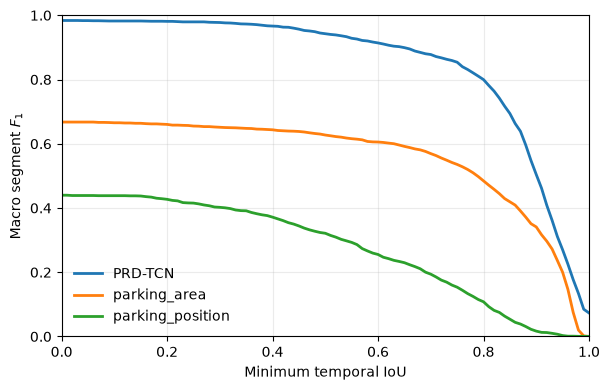

In [9]:
# =============================================================================
# Figure 1: Segment F1 versus minimum temporal IoU
# =============================================================================


def build_paper_iou_results(
    data: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    airport_curves = []

    for (airport, method), group in data.groupby(
        ["airport", "method"],
        sort=False,
    ):
        curve = build_iou_threshold_curve(
            group,
            thresholds=PAPER_IOU_THRESHOLDS,
        )

        curve["airport"] = str(airport)
        curve["method"] = str(method)
        curve["method_label"] = METHOD_LABELS[str(method)]

        airport_curves.append(curve)

    by_airport = pd.concat(
        airport_curves,
        ignore_index=True,
    )

    # Unweighted macro average across the independent test airports.
    macro = (
        by_airport
        .groupby(
            [
                "method",
                "method_label",
                "iou_threshold",
            ],
            as_index=False,
            observed=True,
        )[
            [
                "precision",
                "recall",
                "f1",
            ]
        ]
        .mean()
    )

    return by_airport, macro


segment_iou_by_airport, segment_iou_macro = build_paper_iou_results(
    paper_segment_evaluation
)

segment_iou_by_airport.to_csv(
    paper_output_directory / "segment_f1_iou_by_airport.csv",
    index=False,
)

segment_iou_macro.to_csv(
    paper_output_directory / "segment_f1_iou_macro.csv",
    index=False,
)


# -----------------------------------------------------------------------------
# Publication figure
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.2, 4.0)
)

for method in METHOD_ORDER:
    curve = (
        segment_iou_macro.loc[
            segment_iou_macro["method"].eq(method)
        ]
        .sort_values("iou_threshold")
    )

    if curve.empty:
        continue

    ax.plot(
        curve["iou_threshold"],
        curve["f1"],
        linewidth=2.0,
        label=METHOD_LABELS[method],
    )

ax.set_xlabel("Minimum temporal IoU")
ax.set_ylabel("Macro segment $F_1$")

ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)

ax.grid(
    True,
    alpha=0.25,
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    paper_output_directory / "figure1_segment_f1_vs_iou.pdf",
    bbox_inches="tight",
)

fig.savefig(
    paper_output_directory / "figure1_segment_f1_vs_iou.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
macro_f1_table = (
    segment_iou_macro.loc[
        segment_iou_macro["iou_threshold"].isin([0.5, 0.9]),
        [
            "method_label",
            "iou_threshold",
            "f1",
        ],
    ]
    .pivot(
        index="method_label",
        columns="iou_threshold",
        values="f1",
    )
    .rename(
        columns={
            0.5: "Macro F1 @ IoU 0.5",
            0.9: "Macro F1 @ IoU 0.9",
        }
    )
    .reindex(
        [
            "PRD-TCN",
            "parking_area",
            "parking_position",
        ]
    )
    .round(3)
)

macro_f1_table

iou_threshold,Macro F1 @ IoU 0.5,Macro F1 @ IoU 0.9
method_label,,
PRD-TCN,0.943,0.504
parking_area,0.627,0.341
parking_position,0.321,0.017


### Interactive distributions of segment quality

The following interactive plots show the distributions of the segment-quality
metrics for correctly matched pushback detections.

Only true-positive segment matches are included. The plots compare the PRD-TCN
pipeline with the two rule-based baseline methods.

For each method, the distributions of the following metrics are shown:

- temporal IoU
- absolute start-time error
- absolute end-time error
- absolute duration error
- absolute start-position error
- absolute end-position error

The violin plots show the overall distribution, while the embedded box plots
summarize the median and interquartile range. Individual outliers can be
inspected interactively together with the corresponding airport, season, date,
and flight ID.

In [11]:
# =============================================================================
# Interactive distributions of segment-quality metrics
# =============================================================================

distribution_metrics = {
    "iou": "Temporal IoU",
    "abs_start_error_s": "Absolute start error [s]",
    "abs_end_error_s": "Absolute end error [s]",
    "abs_duration_error_s": "Absolute duration error [s]",
    "abs_start_distance_error_m": "Absolute start distance error [m]",
    "abs_end_distance_error_m": "Absolute end distance error [m]",
}


distribution_data = (
    paper_segment_evaluation.loc[
        paper_segment_evaluation["status"].eq("TP")
    ]
    .copy()
)

distribution_data["method_label"] = (
    distribution_data["method"].map(METHOD_LABELS)
)


for metric, label in distribution_metrics.items():

    data = distribution_data.dropna(
        subset=[metric]
    ).copy()

    fig = px.violin(
        data,
        x="method_label",
        y=metric,
        color="method_label",
        box=True,
        points="outliers",
        hover_data=[
            "airport",
            "season",
            "day",
            "flight_id",
        ],
        category_orders={
            "method_label": [
                "PRD-TCN",
                "parking_area",
                "parking_position",
            ]
        },
        labels={
            "method_label": "Method",
            metric: label,
        },
        title=f"Distribution of {label}",
    )

    fig.update_layout(
        showlegend=False,
        xaxis_title="Method",
        yaxis_title=label,
    )

    fig.show()

### Temporal and spatial boundary accuracy

For correctly matched pushback segments, the start and end boundaries are evaluated using absolute temporal error and direct endpoint-distance error.


In [12]:
# =============================================================================
# Table 2: Temporal and spatial segment boundary quality
# =============================================================================
#
# Only true-positive detections are evaluated here.
#
# Signed temporal errors are defined as:
#
#     predicted boundary time - ground-truth boundary time
#
# Therefore:
#
# Start:
#   negative -> predicted start is too early
#   positive -> predicted start is too late
#
# End:
#   negative -> predicted end is too early
#   positive -> predicted end is too late
#
# Spatial boundary errors are the direct distances in metres between the
# predicted and ground-truth aircraft positions at the respective boundaries.


def summarize_boundary_quality(
    group: pd.DataFrame,
) -> dict:
    return {
        "n_true_positives": int(len(group)),
        "mean_iou": group["iou"].mean(),

        # Temporal boundary errors
        "start_mae_s": group["abs_start_error_s"].mean(),
        "mean_start_error_s": group["start_error_s"].mean(),
        "end_mae_s": group["abs_end_error_s"].mean(),
        "mean_end_error_s": group["end_error_s"].mean(),

        # Direct spatial boundary errors
        "mean_start_distance_error_m": (
            group["start_distance_error_m"].mean()
        ),
        "mean_end_distance_error_m": (
            group["end_distance_error_m"].mean()
        ),
    }


def build_boundary_quality_results(
    data: pd.DataFrame,
) -> pd.DataFrame:
    # Only correctly matched pushbacks with positive temporal overlap.
    true_positives = data.loc[
        data["status"].eq("TP")
    ].copy()

    airport_rows = []

    for (airport, method), group in true_positives.groupby(
        ["airport", "method"],
        sort=False,
    ):
        airport_rows.append(
            {
                "airport": str(airport),
                "method": str(method),
                "method_label": METHOD_LABELS[str(method)],
                **summarize_boundary_quality(group),
            }
        )

    airport_table = pd.DataFrame(airport_rows)

    metric_columns = [
        "mean_iou",
        "start_mae_s",
        "mean_start_error_s",
        "end_mae_s",
        "mean_end_error_s",
        "mean_start_distance_error_m",
        "mean_end_distance_error_m",
    ]

    # Unweighted macro average across airports.
    macro_rows = []

    for method in METHOD_ORDER:
        method_rows = airport_table.loc[
            airport_table["method"].eq(method)
        ]

        if method_rows.empty:
            continue

        row = {
            "airport": "Macro",
            "method": method,
            "method_label": METHOD_LABELS[method],
            "n_true_positives": int(
                method_rows["n_true_positives"].sum()
            ),
        }

        for column in metric_columns:
            row[column] = method_rows[column].mean()

        macro_rows.append(row)

    result = pd.concat(
        [
            airport_table,
            pd.DataFrame(macro_rows),
        ],
        ignore_index=True,
    )

    airport_order = (
        list(
            dict.fromkeys(
                airport_table["airport"].astype(str)
            )
        )
        + ["Macro"]
    )

    result["airport"] = pd.Categorical(
        result["airport"],
        categories=airport_order,
        ordered=True,
    )

    result["method"] = pd.Categorical(
        result["method"],
        categories=METHOD_ORDER,
        ordered=True,
    )

    return (
        result
        .sort_values(["airport", "method"])
        .reset_index(drop=True)
    )


boundary_quality_results = build_boundary_quality_results(
    paper_segment_evaluation
)

# Complete output, including the number of true positives.
boundary_quality_results.to_csv(
    paper_output_directory / "table2_boundary_quality_full.csv",
    index=False,
)

# Compact output intended for the paper / inspection.
table2_boundary_quality = boundary_quality_results[
    [
        "airport",
        "method_label",
        "mean_iou",
        "start_mae_s",
        "mean_start_error_s",
        "end_mae_s",
        "mean_end_error_s",
        "mean_start_distance_error_m",
        "mean_end_distance_error_m",
    ]
].copy()

table2_boundary_quality.to_csv(
    paper_output_directory / "table2_boundary_quality.csv",
    index=False,
)

display(
    table2_boundary_quality.round(3)
)

,airport,method_label,mean_iou,start_mae_s,mean_start_error_s,end_mae_s,mean_end_error_s,mean_start_distance_error_m,mean_end_distance_error_m
0,EBBR,PRD-TCN,0.847,5.071,-2.048,9.976,6.400,1.883,2.482
1,EBBR,parking_area,0.772,12.715,-9.061,14.714,10.762,3.516,5.414
2,EBBR,parking_position,0.659,14.660,13.589,23.921,2.241,19.812,9.819
3,KBOS,PRD-TCN,0.847,6.338,1.159,15.577,-5.228,2.732,8.673
4,KBOS,parking_area,0.891,6.086,-2.131,9.068,3.689,2.977,2.509
5,KBOS,parking_position,0.581,26.506,25.888,36.652,-18.998,22.458,21.128
6,SABE,PRD-TCN,0.896,3.992,2.356,4.941,-0.016,1.979,1.635
7,SABE,parking_area,0.881,3.296,2.681,7.197,0.925,2.524,10.852
8,SABE,parking_position,0.681,24.491,24.491,16.906,6.981,22.433,3.721
9,Macro,PRD-TCN,0.864,5.133,0.489,10.165,0.385,2.198,4.263


In [13]:
# =============================================================================
# Paired boundary-quality comparison
# =============================================================================
#
# For each PRD-TCN vs baseline comparison, only flights for which BOTH methods
# correctly detected an overlapping pushback segment (status == "TP") are used.
#
# This ensures that boundary quality is compared on exactly the same flights.
#
# The common-flight set is determined separately for each airport.


METHOD_PAIRS = [
    ("prediction", "parking_area"),
    ("prediction", "parking_position"),
]


def build_paired_boundary_quality_results(
    data: pd.DataFrame,
) -> pd.DataFrame:

    true_positives = data.loc[
        data["status"].eq("TP")
    ].copy()

    rows = []

    airports = list(
        dict.fromkeys(true_positives["airport"].astype(str))
    )

    for method_a, method_b in METHOD_PAIRS:

        comparison_label = (
            f"{METHOD_LABELS[method_a]} vs {METHOD_LABELS[method_b]}"
        )

        for airport in airports:

            airport_data = true_positives.loc[
                true_positives["airport"].astype(str).eq(airport)
            ]

            flights_a = set(
                airport_data.loc[
                    airport_data["method"].eq(method_a),
                    "flight_key",
                ].astype(str)
            )

            flights_b = set(
                airport_data.loc[
                    airport_data["method"].eq(method_b),
                    "flight_key",
                ].astype(str)
            )

            # Only flights correctly detected by both methods.
            common_flights = flights_a & flights_b

            if not common_flights:
                continue

            for method in [method_a, method_b]:

                method_data = airport_data.loc[
                    airport_data["method"].eq(method)
                    & airport_data["flight_key"].astype(str).isin(
                        common_flights
                    )
                ].copy()

                rows.append(
                    {
                        "comparison": comparison_label,
                        "airport": airport,
                        "method": method,
                        "method_label": METHOD_LABELS[method],
                        "n_common_true_positives": len(common_flights),
                        **summarize_boundary_quality(method_data),
                    }
                )

    by_airport = pd.DataFrame(rows)

    metric_columns = [
        "mean_iou",
        "start_mae_s",
        "mean_start_error_s",
        "end_mae_s",
        "mean_end_error_s",
        "mean_start_distance_error_m",
        "mean_end_distance_error_m",
    ]

    # -------------------------------------------------------------------------
    # Unweighted macro average across airports
    # -------------------------------------------------------------------------

    macro_rows = []

    for comparison in by_airport["comparison"].unique():

        comparison_data = by_airport.loc[
            by_airport["comparison"].eq(comparison)
        ]

        for method in comparison_data["method"].unique():

            method_rows = comparison_data.loc[
                comparison_data["method"].eq(method)
            ]

            row = {
                "comparison": comparison,
                "airport": "Macro",
                "method": method,
                "method_label": METHOD_LABELS[method],
                "n_common_true_positives": int(
                    method_rows["n_common_true_positives"].sum()
                ),
                "n_true_positives": int(
                    method_rows["n_true_positives"].sum()
                ),
            }

            for column in metric_columns:
                row[column] = method_rows[column].mean()

            macro_rows.append(row)

    result = pd.concat(
        [
            by_airport,
            pd.DataFrame(macro_rows),
        ],
        ignore_index=True,
    )

    return result


paired_boundary_quality = build_paired_boundary_quality_results(
    paper_segment_evaluation
)


# Save complete results.
paired_boundary_quality.to_csv(
    paper_output_directory / "paired_boundary_quality.csv",
    index=False,
)


# Compact table for inspection.
paired_boundary_quality_display = paired_boundary_quality[
    [
        "comparison",
        "airport",
        "method_label",
        "n_common_true_positives",
        "mean_iou",
        "start_mae_s",
        "mean_start_error_s",
        "end_mae_s",
        "mean_end_error_s",
        "mean_start_distance_error_m",
        "mean_end_distance_error_m",
    ]
].copy()


display(
    paired_boundary_quality_display.round(3)
)

,comparison,airport,method_label,n_common_true_positives,mean_iou,start_mae_s,mean_start_error_s,end_mae_s,mean_end_error_s,mean_start_distance_error_m,mean_end_distance_error_m
0,PRD-TCN vs parking_area,EBBR,PRD-TCN,624,0.863,4.623,-1.800,7.611,5.104,1.812,1.655
1,PRD-TCN vs parking_area,EBBR,parking_area,624,0.773,12.614,-8.954,14.534,10.982,3.518,5.367
2,PRD-TCN vs parking_area,KBOS,PRD-TCN,222,0.882,5.293,1.167,11.694,-1.982,2.930,6.015
3,PRD-TCN vs parking_area,KBOS,parking_area,222,0.891,6.086,-2.131,9.068,3.689,2.977,2.509
4,PRD-TCN vs parking_area,SABE,PRD-TCN,352,0.905,3.790,2.705,4.438,-0.472,1.940,1.369
5,PRD-TCN vs parking_area,SABE,parking_area,352,0.885,3.355,2.724,7.179,0.838,2.565,10.989
6,PRD-TCN vs parking_position,EBBR,PRD-TCN,394,0.859,4.589,-0.746,10.863,6.949,1.874,2.581
7,PRD-TCN vs parking_position,EBBR,parking_position,394,0.659,14.660,13.589,23.921,2.241,19.812,9.819
8,PRD-TCN vs parking_position,KBOS,PRD-TCN,410,0.862,6.529,2.080,13.732,-3.298,3.409,8.027
9,PRD-TCN vs parking_position,KBOS,parking_position,410,0.581,26.537,25.917,36.737,-19.049,22.480,21.180


## 6. Summary

The final cell prints the main flight-level, segment-level, and boundary-accuracy results together with the output directory.


In [ ]:
# =============================================================================
# Final summary
# =============================================================================

unique_all = flight_evaluation["flight_key"].nunique()

unique_not_clear = (
    flight_evaluation.loc[
        flight_evaluation["is_not_clear"].fillna(False),
        "flight_key",
    ]
    .nunique()
)

unique_used = paper_flight_evaluation["flight_key"].nunique()

print("\n" + "=" * 79)
print("PAPER EVALUATION COMPLETE")
print("=" * 79)

print(
    "Use cache for:       "
    + (
        ", ".join(
            method
            for method in METHOD_ORDER
            if method in USE_CACHE_FOR
        )
        if USE_CACHE_FOR
        else "none"
    )
)
print(f"Include not clear:   {INCLUDE_NOT_CLEAR}")
print(f"All labelled flights:{unique_all:>8,}")
print(f"Not-clear flights:   {unique_not_clear:>8,}")
print(f"Flights used:        {unique_used:>8,}")
print(f"Results directory:   {paper_output_directory}")

print("\nTABLE 1 — PUSHBACK DETECTION")
print(
    table1_detection
    .round(4)
    .to_string(index=False)
)

print("\nTABLE 2 — TEMPORAL SEGMENT QUALITY")
print(
    table2_boundary_quality
    .round(3)
    .to_string(index=False)
)

print("\nFIGURE 1")
print(
    paper_output_directory
    / "figure1_segment_f1_vs_iou.pdf"
)

print("=" * 79)


PAPER EVALUATION COMPLETE
Use cache for:       none
Include not clear:   False
All labelled flights:   3,167
Not-clear flights:         23
Flights used:           3,144
Results directory:   /cluster/home/hanv/Projects/OSN_pushback_detection/results/evaluation/paper_results/without_not_clear

TABLE 1 — PUSHBACK DETECTION
airport     method_label  precision  recall     f1  specificity  balanced_accuracy
   EBBR          PRD-TCN     0.9953  0.9942 0.9947       0.9727             0.9834
   EBBR     parking_area     0.9342  0.7301 0.8197       0.8636             0.7969
   EBBR parking_position     0.7086  0.4603 0.5581       0.9727             0.7165
   KBOS          PRD-TCN     0.9917  0.9847 0.9882       0.9815             0.9831
   KBOS     parking_area     0.7817  0.2618 0.3922       0.9593             0.6105
   KBOS parking_position     0.8422  0.4847 0.6153       0.9889             0.7368
   SABE          PRD-TCN     0.9693  0.9675 0.9684       0.9758             0.9716
   SABE     p